# ParkFlow1 — Parking Data Analytics

**Dataset:** IIoT Smart Parking Management Dataset (Kaggle)

This notebook explores the parking dataset using Pandas and Matplotlib. It checks data quality, summarizes occupancy and payments, analyzes entry hours and parking sections, and creates visualizations.

> Note: this dataset appears to contain 1,000 records and 28 columns. Treat findings as patterns in this dataset, not live conditions at a real parking lot. Confirm the unit of `Parking_Duration` from the dataset documentation before describing it as hours.


**Standalone version:** the original dataset is embedded in this notebook, so you do not need a separate CSV file. The analysis sections and their order are preserved.


Install

In [1]:

%pip install pandas matplotlib


Note: you may need to restart the kernel to use updated packages.


## 1. Import libraries

In [ ]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 120)


/home/oai/.config/matplotlib is not a writable directory


Matplotlib created a temporary cache directory at /tmp/matplotlib-67s85olv because there was an issue with the default path (/home/oai/.config/matplotlib); it is highly recommended to set the MPLCONFIGDIR environment variable to a writable directory, in particular to speed up the import of Matplotlib and to better support multiprocessing.


## 2. Load the dataset

In [2]:

from pathlib import Path
import pandas as pd

DATA_PATH = (
    Path.cwd()
    / "data"
    / "IIoT_Smart_Parking_Management.csv"
)

df = pd.read_csv(DATA_PATH)

print("Dataset shape:", df.shape)
display(df.head())


Dataset shape: (1000, 28)


,imestamp,Parking_Spot_ID,Sensor_Reading_Proximity,Sensor_Reading_Pressure,Vehicle_Type_Weight,Vehicle_Type_Height,User_Type,Weather_Temperature,Weather_Precipitation,Nearby_Traffic_Level,...,Occupancy_Status,Vehicle_Type,Parking_Violation,Sensor_Reading_Ultrasonic,Parking_Duration,Environmental_Noise_Level,Dynamic_Pricing_Factor,Spot_Size,Proximity_To_Exit,User_Parking_History
0,2021-01-01 00:00:00.000000000,20,1.023651,1.541461,1831.770127,4.392528,Visitor,18.092553,1,Low,...,Occupied,Car,0,102.951052,4,55.620740,0.8,Standard,6.610474,6.660310
1,2021-01-02 06:39:16.756756756,49,3.903349,1.621719,1330.815754,4.595638,Registered,13.397533,0,Low,...,Occupied,Car,0,87.559131,3,56.682386,1.2,Compact,8.678719,6.766187
2,2021-01-03 13:18:33.513513513,38,10.315709,6.292374,1255.134827,4.313721,Registered,21.687410,0,High,...,Vacant,Car,1,100.061854,5,59.239322,0.8,Standard,13.795262,-0.910052
3,2021-01-04 19:57:50.270270270,31,6.588039,1.659870,1523.442919,3.567329,Visitor,18.683461,0,Medium,...,Vacant,Motorcycle,1,110.594598,2,44.545155,0.8,Standard,1.678721,10.415888
4,2021-01-06 02:37:07.027027027,8,8.213969,3.278467,1758.490837,5.145836,Visitor,19.214876,0,High,...,Occupied,Car,0,84.786963,2,48.012604,0.8,Standard,20.012252,4.355544


## 3. Explore structure and data quality

In [ ]:
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 28 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   Timestamp                  1000 non-null   object 
 1   Parking_Spot_ID            1000 non-null   int64  
 2   Sensor_Reading_Proximity   1000 non-null   float64
 3   Sensor_Reading_Pressure    1000 non-null   float64
 4   Vehicle_Type_Weight        1000 non-null   float64
 5   Vehicle_Type_Height        1000 non-null   float64
 6   User_Type                  1000 non-null   object 
 7   Weather_Temperature        1000 non-null   float64
 8   Weather_Precipitation      1000 non-null   int64  
 9   Nearby_Traffic_Level       1000 non-null   object 
 10  Entry_Time                 1000 non-null   int64  
 11  Exit_Time                  1000 non-null   int64  
 12  Electric_Vehicle           1000 non-null   int64  
 13  Reserved_Status            1000 non-null   int64 

In [ ]:
print("Missing values per column:")
display(df.isna().sum().sort_values(ascending=False).to_frame("missing_count"))

print("Exact duplicate rows:", int(df.duplicated().sum()))


Missing values per column:


,missing_count
Timestamp,0
Parking_Spot_ID,0
Sensor_Reading_Proximity,0
Sensor_Reading_Pressure,0
Vehicle_Type_Weight,0
Vehicle_Type_Height,0
User_Type,0
Weather_Temperature,0
Weather_Precipitation,0
Nearby_Traffic_Level,0


Exact duplicate rows: 0


In [ ]:
print("Column names:")
for column in df.columns:
    print("-", column)


Column names:
- Timestamp
- Parking_Spot_ID
- Sensor_Reading_Proximity
- Sensor_Reading_Pressure
- Vehicle_Type_Weight
- Vehicle_Type_Height
- User_Type
- Weather_Temperature
- Weather_Precipitation
- Nearby_Traffic_Level
- Entry_Time
- Exit_Time
- Electric_Vehicle
- Reserved_Status
- Occupancy_Rate
- Payment_Amount
- Parking_Lot_Section
- Payment_Status
- Occupancy_Status
- Vehicle_Type
- Parking_Violation
- Sensor_Reading_Ultrasonic
- Parking_Duration
- Environmental_Noise_Level
- Dynamic_Pricing_Factor
- Spot_Size
- Proximity_To_Exit
- User_Parking_History


## 4. Clean data types and text values

In [ ]:
# Keep the original dataset unchanged and work on a cleaned copy.
clean_df = df.copy()

print("Rows and columns before cleaning:", df.shape)
print("Missing values before cleaning:", int(df.isna().sum().sum()))
print("Duplicate rows before cleaning:", int(df.duplicated().sum()))

# 1. Convert the full calendar timestamp to datetime.
if "Timestamp" in clean_df.columns:
    clean_df["Timestamp"] = pd.to_datetime(clean_df["Timestamp"], errors="coerce")

# 2. Remove leading/trailing spaces from text and treat blank text as missing.
text_columns = clean_df.select_dtypes(include=["object", "string"]).columns
for column in text_columns:
    clean_df[column] = clean_df[column].astype("string").str.strip()
    clean_df[column] = clean_df[column].replace("", pd.NA)

# 3. Convert columns that should be numeric.
numeric_columns = [
    "Parking_Spot_ID", "Sensor_Reading_Proximity", "Sensor_Reading_Pressure",
    "Vehicle_Type_Weight", "Vehicle_Type_Height", "Weather_Temperature",
    "Weather_Precipitation", "Entry_Time", "Exit_Time", "Electric_Vehicle",
    "Reserved_Status", "Occupancy_Rate", "Payment_Amount", "Parking_Violation",
    "Sensor_Reading_Ultrasonic", "Parking_Duration", "Environmental_Noise_Level",
    "Dynamic_Pricing_Factor", "Proximity_To_Exit", "User_Parking_History"
]
for column in numeric_columns:
    if column in clean_df.columns:
        clean_df[column] = pd.to_numeric(clean_df[column], errors="coerce")

# 4. Show what changed. Invalid values converted to NaN are reviewed in the next step.
print("Rows and columns after type/text cleaning:", clean_df.shape)
print("Missing values after cleaning:", int(clean_df.isna().sum().sum()))
print("Duplicate rows after cleaning (not removed automatically):", int(clean_df.duplicated().sum()))
print("New missing values by column:")
new_missing = clean_df.isna().sum() - df.isna().sum()
display(new_missing[new_missing > 0].sort_values(ascending=False).to_frame("new_missing_values"))
display(clean_df.head())


Rows and columns before cleaning: (1000, 28)
Missing values before cleaning: 0
Duplicate rows before cleaning: 0
Rows and columns after type/text cleaning: (1000, 28)
Missing values after cleaning: 0
Duplicate rows after cleaning (not removed automatically): 0
New missing values by column:


,new_missing_values


,Timestamp,Parking_Spot_ID,Sensor_Reading_Proximity,Sensor_Reading_Pressure,Vehicle_Type_Weight,Vehicle_Type_Height,User_Type,Weather_Temperature,Weather_Precipitation,Nearby_Traffic_Level,Entry_Time,Exit_Time,Electric_Vehicle,Reserved_Status,Occupancy_Rate,Payment_Amount,Parking_Lot_Section,Payment_Status,Occupancy_Status,Vehicle_Type,Parking_Violation,Sensor_Reading_Ultrasonic,Parking_Duration,Environmental_Noise_Level,Dynamic_Pricing_Factor,Spot_Size,Proximity_To_Exit,User_Parking_History
0,2021-01-01 00:00:00.000000000,20,1.023651,1.541461,1831.770127,4.392528,Visitor,18.092553,1,Low,18,9,0,1,0.573909,2.289774,Zone A,Paid,Occupied,Car,0,102.951052,4,55.620740,0.8,Standard,6.610474,6.660310
1,2021-01-02 06:39:16.756756756,49,3.903349,1.621719,1330.815754,4.595638,Registered,13.397533,0,Low,3,13,1,0,0.161778,0.671983,Zone A,Unpaid,Occupied,Car,0,87.559131,3,56.682386,1.2,Compact,8.678719,6.766187
2,2021-01-03 13:18:33.513513513,38,10.315709,6.292374,1255.134827,4.313721,Registered,21.687410,0,High,13,1,0,0,0.135114,0.828293,Zone B,Paid,Vacant,Car,1,100.061854,5,59.239322,0.8,Standard,13.795262,-0.910052
3,2021-01-04 19:57:50.270270270,31,6.588039,1.659870,1523.442919,3.567329,Visitor,18.683461,0,Medium,15,15,0,0,0.236755,14.273131,Zone B,Paid,Vacant,Motorcycle,1,110.594598,2,44.545155,0.8,Standard,1.678721,10.415888
4,2021-01-06 02:37:07.027027027,8,8.213969,3.278467,1758.490837,5.145836,Visitor,19.214876,0,High,19,18,1,1,0.164526,5.884323,Zone C,Paid,Occupied,Car,0,84.786963,2,48.012604,0.8,Standard,20.012252,4.355544


## 5. Validate important columns

In [ ]:
issues = []

required_columns = [
    "Timestamp", "Parking_Spot_ID", "Entry_Time", "Exit_Time",
    "Occupancy_Rate", "Payment_Amount", "Parking_Lot_Section",
    "Payment_Status", "Occupancy_Status", "Vehicle_Type",
    "Parking_Duration", "Parking_Violation"
]
missing_columns = [c for c in required_columns if c not in clean_df.columns]
if missing_columns:
    issues.append(f"Missing required columns: {missing_columns}")

# Check required fields for missing values.
for column in [c for c in required_columns if c in clean_df.columns]:
    missing_count = int(clean_df[column].isna().sum())
    if missing_count:
        issues.append(f"{column}: {missing_count} missing/invalid values")

# Entry and exit are hours of day in this dataset (0–23).
if "Entry_Time" in clean_df.columns:
    bad_entry = clean_df["Entry_Time"].notna() & ~clean_df["Entry_Time"].between(0, 23)
    issues.append(f"Entry_Time outside 0–23: {int(bad_entry.sum())}")

if "Exit_Time" in clean_df.columns:
    bad_exit = clean_df["Exit_Time"].notna() & ~clean_df["Exit_Time"].between(0, 23)
    issues.append(f"Exit_Time outside 0–23: {int(bad_exit.sum())}")

# These values should not be negative.
for column in ["Parking_Duration", "Payment_Amount", "Parking_Spot_ID"]:
    if column in clean_df.columns:
        negative_count = int((clean_df[column] < 0).fillna(False).sum())
        if negative_count:
            issues.append(f"{column}: {negative_count} negative values")

if "Occupancy_Rate" in clean_df.columns:
    bad_rate = clean_df["Occupancy_Rate"].notna() & ~clean_df["Occupancy_Rate"].between(0, 1)
    if bad_rate.any():
        issues.append(f"Occupancy_Rate outside 0–1: {int(bad_rate.sum())}")

if "Parking_Violation" in clean_df.columns:
    bad_violation = clean_df["Parking_Violation"].notna() & ~clean_df["Parking_Violation"].isin([0, 1])
    if bad_violation.any():
        issues.append(f"Parking_Violation not 0 or 1: {int(bad_violation.sum())}")

if "Occupancy_Status" in clean_df.columns:
    print("Occupancy_Status values:")
    display(clean_df["Occupancy_Status"].value_counts(dropna=False).to_frame("records"))

print("Validation notes:")
if issues:
    for issue in issues:
        print("-", issue)
else:
    print("No validation issues found in the checked columns.")

print("Note: validation reports issues; it does not automatically delete rows.")


Occupancy_Status values:


,records
Occupancy_Status,
Occupied,550
Vacant,450


Validation notes:
- Entry_Time outside 0–23: 0
- Exit_Time outside 0–23: 0
Note: validation reports issues; it does not automatically delete rows.


## 6. Summary metrics

In [ ]:
summary = {
    "Total records": len(clean_df),
    "Occupied records": int(clean_df["Occupancy_Status"].astype(str).str.casefold().eq("occupied").sum()),
    "Vacant records": int(clean_df["Occupancy_Status"].astype(str).str.casefold().eq("vacant").sum()),
    "Average parking duration (dataset units)": round(clean_df["Parking_Duration"].mean(), 2),
    "Average occupancy rate (%)": round(clean_df["Occupancy_Rate"].mean() * 100, 2),
    "Total payment amount (dataset units)": round(clean_df["Payment_Amount"].sum(), 2),
    "Average payment amount (dataset units)": round(clean_df["Payment_Amount"].mean(), 2),
}
display(pd.DataFrame(summary.items(), columns=["Metric", "Value"]))


,Metric,Value
0,Total records,1000.00
1,Occupied records,550.00
2,Vacant records,450.00
3,Average parking duration (dataset units),2.87
4,Average occupancy rate (%),28.37
5,Total payment amount (dataset units),10523.83
6,Average payment amount (dataset units),10.52


## 7. Entry activity by hour

In [ ]:
peak_hours = (
    clean_df.groupby("Entry_Time", dropna=True)
    .size()
    .reset_index(name="records")
    .sort_values("records", ascending=False)
)
display(peak_hours.head(10))


,Entry_Time,records
14,14,54
20,20,53
22,22,52
17,17,50
16,16,49
19,19,46
3,3,45
6,6,43
15,15,43
2,2,42


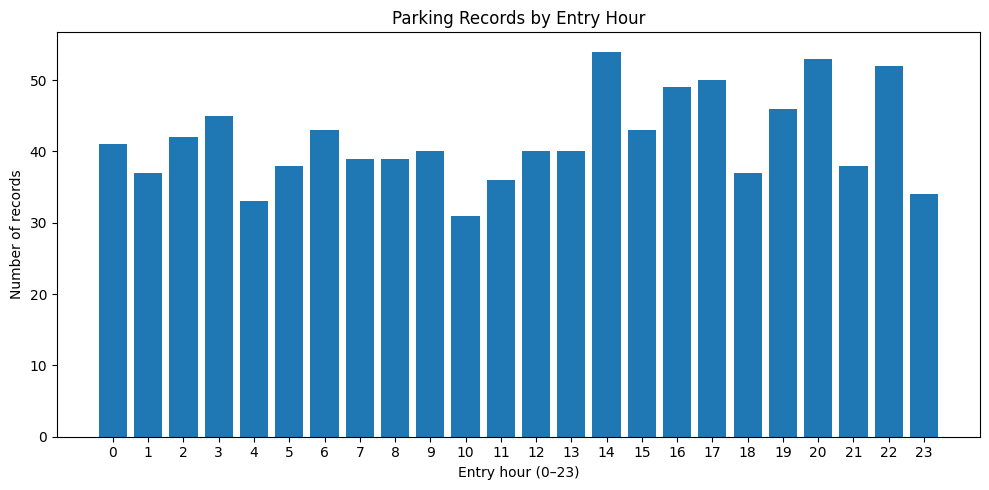

In [ ]:
hourly = peak_hours.sort_values("Entry_Time")
plt.figure(figsize=(10, 5))
plt.bar(hourly["Entry_Time"].astype(int).astype(str), hourly["records"])
plt.title("Parking Records by Entry Hour")
plt.xlabel("Entry hour (0–23)")
plt.ylabel("Number of records")
plt.tight_layout()
plt.show()


## 8. Occupancy by parking section

In [ ]:
section_summary = (
    clean_df.assign(
        _occupied=clean_df["Occupancy_Status"].astype(str).str.casefold().eq("occupied")
    )
    .groupby("Parking_Lot_Section", dropna=False)
    .agg(
        records=("Occupancy_Status", "size"),
        occupied_records=("_occupied", "sum"),
        occupied_share=("_occupied", "mean")
    )
    .reset_index()
)
section_summary["occupied_share_percent"] = (section_summary["occupied_share"] * 100).round(2)
display(section_summary.sort_values("occupied_share_percent", ascending=False))


,Parking_Lot_Section,records,occupied_records,occupied_share,occupied_share_percent
0,Zone A,382,218,0.570681,57.07
1,Zone B,307,174,0.566775,56.68
3,Zone D,114,62,0.543860,54.39
2,Zone C,197,96,0.487310,48.73


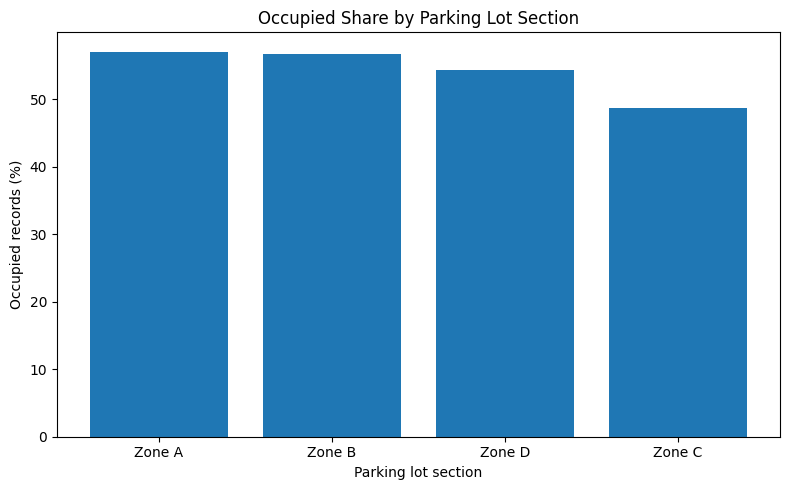

In [ ]:
plot_sections = section_summary.sort_values("occupied_share_percent", ascending=False)
plt.figure(figsize=(8, 5))
plt.bar(plot_sections["Parking_Lot_Section"].astype(str), plot_sections["occupied_share_percent"])
plt.title("Occupied Share by Parking Lot Section")
plt.xlabel("Parking lot section")
plt.ylabel("Occupied records (%)")
plt.tight_layout()
plt.show()


## 9. Payment status and amount

In [ ]:
payment_summary = (
    clean_df.groupby("Payment_Status", dropna=False)
    .agg(
        records=("Payment_Status", "size"),
        total_amount=("Payment_Amount", "sum"),
        average_amount=("Payment_Amount", "mean")
    )
    .reset_index()
    .round(2)
)
display(payment_summary)


,Payment_Status,records,total_amount,average_amount
0,Overdue,108,1087.51,10.07
1,Paid,690,7299.45,10.58
2,Unpaid,202,2136.87,10.58


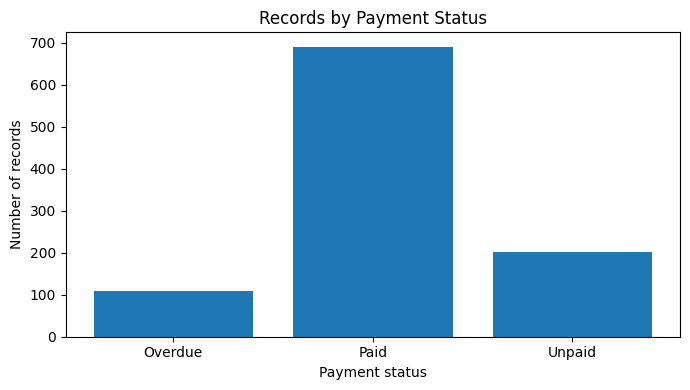

In [ ]:
plt.figure(figsize=(7, 4))
plt.bar(payment_summary["Payment_Status"].astype(str), payment_summary["records"])
plt.title("Records by Payment Status")
plt.xlabel("Payment status")
plt.ylabel("Number of records")
plt.tight_layout()
plt.show()


## 10. Vehicle type comparison

In [ ]:
vehicle_summary = (
    clean_df.groupby("Vehicle_Type", dropna=False)
    .agg(
        records=("Vehicle_Type", "size"),
        average_duration=("Parking_Duration", "mean"),
        average_payment=("Payment_Amount", "mean")
    )
    .reset_index()
    .round(2)
)
display(vehicle_summary)


,Vehicle_Type,records,average_duration,average_payment
0,Car,704,2.91,10.53
1,Electric Vehicle,105,2.63,12.22
2,Motorcycle,191,2.87,9.57


## 11. Data-driven insights

In [ ]:
insights = []
total = len(clean_df)
occupied_share = clean_df["Occupancy_Status"].astype(str).str.casefold().eq("occupied").mean() * 100
insights.append(f"The dataset contains {total} records.")
insights.append(f"{occupied_share:.1f}% of records are labelled Occupied.")

if not peak_hours.empty:
    peak = peak_hours.iloc[0]
    insights.append(f"The most frequent entry hour is {int(peak['Entry_Time']):02d}:00, with {int(peak['records'])} records.")

if not section_summary.empty:
    top_section = section_summary.sort_values("occupied_share_percent", ascending=False).iloc[0]
    insights.append(f"{top_section['Parking_Lot_Section']} has the highest occupied share ({top_section['occupied_share_percent']:.1f}%) in this dataset.")

if not payment_summary.empty:
    top_payment = payment_summary.sort_values("records", ascending=False).iloc[0]
    insights.append(f"The most common payment status is {top_payment['Payment_Status']} ({int(top_payment['records'])} records).")

for i, insight in enumerate(insights, start=1):
    print(f"{i}. {insight}")


1. The dataset contains 1000 records.
2. 55.0% of records are labelled Occupied.
3. The most frequent entry hour is 14:00, with 54 records.
4. Zone A has the highest occupied share (57.1%) in this dataset.
5. The most common payment status is Paid (690 records).


## 12. Interpretation notes and limitations
- `Entry_Time` and `Exit_Time` are hours of day (0–23), not full timestamps.
- `Exit_Time` earlier than `Entry_Time` could indicate overnight parking; do not automatically label it an error without documentation.
- The unit for `Parking_Duration` is not confirmed by the provided metadata.
- `Occupancy_Status` is a row-level label. A percentage of occupied rows is not necessarily the real-time occupancy of physical spots.
- `Payment_Amount` sum should not be described as real revenue unless each row represents a separate payment and currency/units are confirmed.
- This is a Kaggle dataset, not a live connection to ParkFlow.
